# 26 · VAE 분포 읽기: β·warmup·조건부 생성

**이번 질문:** 복원이 좋아졌는데 prior에서 뽑은 점이 어색하다면, encoder의 분포와 decoder의 사용법 중 어디를 보아야 할까요?

두 품종 과일의 **붉기·무게를 나타내는 가상 측정값 두 개**를 사용합니다. 실제 과일 자료가 아니라, 조건별로 휘어진 띠를 만드는 합성 예제입니다. MNIST의 784개 화소 대신 두 좌표만 써서 분포와 계산을 직접 봅니다.

- 준비물: [12 Gaussian·정보이론](../02_연결/12_gaussian_information.ipynb)의 Gaussian·KL, [15 실험과 평가](../02_연결/15_experiments_evaluation.ipynb)의 자료 분할, [25 VAE](25_vae.ipynb)의 재매개화·역전파, [27 Monte Carlo](27_monte_carlo_gradients.ipynb)의 표본 평균·표준오차입니다. 갱신은 [04 Adam](../00_기초/04_optimizers.ipynb)을 다시 구현합니다.
- 도착점: posterior와 prior, β 목적과 ELBO, decoder 평균과 실제 생성 표본을 구분하고, 작은 조건부 VAE를 직접 학습·검산합니다.
- 연결: 25번의 조건 없는 VAE에 품종 정보를 추가합니다. 평가의 한계는 [37 생성 모델 평가](37_generative_evaluation.ipynb)와 함께 읽습니다.
- 실행: 외부 데이터 다운로드 없이 NumPy·CPU로 실행합니다. 실험 조건은 결과를 보기 전에 고정합니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 수식과 구현 | shape와 줄별 대응을 적습니다 |
| 🔍 확인 | 그림과 검산 | 항등식과 관측 결과를 구분합니다 |
| 📎 참고 | 배경과 코드 | 필요한 자리에서 확인합니다 |
| ✏️ 연습 | 한두 줄 직접 구현 | 독립 손계산으로 검사합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. $q(z\mid x,c)$는 입력별 근사 posterior이고, 생성은 고정 prior $p(z)=\mathcal N(0,I)$에서 시작합니다. 모인 posterior의 평균·분산만으로 두 분포의 일치를 판단하지 않습니다.
2. 학습 목적 $R+\beta K$와 모든 후보의 공통 평가 $R+K$를 분리합니다. warmup은 갱신 경로를 바꾸며 성공을 보장하지 않습니다.
3. 작은 KL·잠재 평균 분산·decoder 민감도는 서로 다른 단서입니다. 같은 예산의 실제 학습 결과와 의도적으로 만든 collapse 통제를 구분합니다.

| 기호 | shape | 축의 의미 |
|---|---|---|
| $X,C$ | $(N,2),(N,2)$ | 관측 N개·측정 2개 / 품종의 one-hot 2개 |
| $\mu,\ell,\epsilon,Z$ | $(N,L)$ | 관측 축·잠재 축, 본 실험 $L=2$ |
| $H_e,H_d$ | $(N,H)$ | encoder·decoder 은닉값, 본 실험 $H=12$ |
| $m$ | $(N,2)$ | Gaussian 관측 평균 |
| $\epsilon^{eval}$ | $(K,N,L)$ | 독립 반복 K·고정 평가 관측 N·잠재 L |
| $R_k$ | $(K,)$ | 매 반복에서 관측 평균한 재구성 항 |

[전체 경로](../../docs/CURRICULUM.md) · [글 규칙](../../docs/WRITING.md) · [그림 설계](../../docs/DESIGN.md) · [그림 보조 코드](../../src/utils/vae_distribution_plots.py)

In [1]:
# 준비 셀: 실행만 하고 넘어가도 됩니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/utils/plotting.py").is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.utils import setup_plots, run_check
from src.utils.vae_distribution_plots import (
    plot_distribution_roles, plot_beta_schedule, plot_conditional_flow,
    plot_evaluation_flow, plot_learning, plot_test_metrics,
    plot_generation_path, plot_generated_comparison, plot_latent_diagnostics,
)
setup_plots()
print("NumPy", np.__version__, "· 모든 계산은 float64 · 다운로드 없음")

NumPy 2.4.6 · 모든 계산은 float64 · 다운로드 없음


### 📎 모델과 자료의 약속

> **용어**
>
> - **조건(condition) $c$**: 생성할 때 사용자가 정하는 품종 정보입니다. 두 품종을 `[1,0]`, `[0,1]`의 **one-hot**, 즉 선택한 칸만 1인 벡터로 나타냅니다.
> - **encoder $q_\phi(z\mid x,c)$**: 관측과 조건을 받아 잠재 Gaussian의 평균·로그 분산을 계산하는 신경망입니다.
> - **decoder $p_\theta(x\mid z,c)$**: 잠재와 조건을 받아 관측 Gaussian의 평균을 계산하는 신경망입니다. 관측 표준편차 $s=0.25$는 모든 실험에서 고정합니다.
> - **학습 파라미터 $\phi,\theta$**: encoder와 decoder의 가중치·편향 배열 전체입니다. `p`라는 사전(dictionary)에 이름별로 저장하며, 밀도 기호 $p_\theta$와 Python 변수 `p`는 표기 역할이 다릅니다.
>
> **코드**
>
> - `np.random.default_rng(seed)`: 따로 관리하는 난수 생성기입니다. seed는 재현할 난수열의 시작 번호입니다.
> - `a[:, None]`: 길이 N인 배열에 열 축을 추가해 `(N,1)`로 만듭니다. `a[None, :]`는 행 축을 추가합니다.
> - `sum(axis=1)`은 각 관측 안의 좌표를 합합니다. `mean(axis=0)`은 관측들을 평균내어 좌표별 값을 남깁니다.

## 🔑 1. 한 과일의 posterior와 새 과일의 prior를 구별합니다

**이 절에서 가져갈 것:** 입력별 $q$와 생성용 $p$는 역할이 다르며, 개별 KL과 모인 분포의 모양을 함께 읽습니다.

같은 품종에서도 붉기·무게가 다르면 encoder가 내놓는 잠재 위치가 다릅니다. 새 과일을 만들 때는 그 입력 과일이 없으므로 encoder 대신 prior에서 시작합니다.

> **용어**
>
> - **사전분포(prior)**: 입력 관측을 보기 전에 잠재를 뽑는 분포입니다. 여기서는 조건과 무관한 $p(z\mid c)=p(z)=\mathcal N(0,I)$입니다.
> - **사후분포(posterior)**: 모델이 관측을 본 뒤 갖는 잠재 분포 $p_\theta(z\mid x,c)$입니다. encoder의 $q_\phi$는 이를 근사하며 일반적으로 정확히 같지는 않습니다.
> - **모인 posterior(aggregated posterior)**: 자료의 여러 $q(z\mid x,c)$를 그 자료의 비중으로 섞은 분포입니다. 잠재 평균들만 찍은 산점도와도 다릅니다.
> - **KL divergence**: 두 분포의 차이를 로그 밀도비의 기대값으로 재는 값입니다. 대칭인 거리가 아니며 자연로그를 쓰는 단위는 **nat**입니다.

$$q_n(z)=\mathcal N(\mu_n,\operatorname{diag}(e^{\ell_n})),\qquad
K_{nj}=\tfrac12\{\mu_{nj}^2+e^{\ell_{nj}}-1-\ell_{nj}\},\qquad
\bar K=\frac1N\sum_n\sum_j K_{nj}.$$

$\mu,\ell,K$는 `(N,L)`입니다. 잠재 축을 먼저 **합**하고 관측 축을 **평균**합니다. $\ell=\log\sigma^2$이므로 표준편차는 $e^{\ell/2}$입니다.

한 조건 안의 두 관측에 대해 $\mu=(-0.8,0.8)$, $\sigma=0.6$으로 정합니다. 각 KL은 $\frac12(0.64+0.36-1-\log0.36)\approx0.511$입니다. 두 q를 반씩 섞으면 평균은 0, 분산은 $0.6^2+0.8^2=1$이지만 표준정규와 같은 밀도는 아닙니다.

> **코드** · `np.full_like(mu, value)`는 μ와 같은 모양을 한 값으로 채웁니다. `ravel()`은 값의 순서를 유지하며 한 줄로 펼쳐 출력합니다.

In [2]:
q_grid = np.linspace(-3.0, 3.0, 301)
q_mu = np.array([[-0.8], [0.8]])
q_logvar = np.full_like(q_mu, np.log(0.36))
q_density = np.exp(-0.5 * ((q_grid[None, :] - q_mu) / 0.6)**2) / (0.6 * np.sqrt(2.0 * np.pi))
prior_density = np.exp(-0.5 * q_grid**2) / np.sqrt(2.0 * np.pi)
aggregate_density = q_density.mean(axis=0)
kl_direct = 0.5 * (q_mu**2 + np.exp(q_logvar) - 1.0 - q_logvar)
kl_loop = np.zeros_like(q_mu)
for n in range(2):
    for j in range(1):
        kl_loop[n, j] = 0.5 * (q_mu[n, j]**2 + np.exp(q_logvar[n, j]) - 1.0 - q_logvar[n, j])
print("손계산 KL:", -0.5 * np.log(0.36), "· 반복문:", kl_loop.ravel())

손계산 KL: 0.5108256237659907 · 반복문: [0.51082562 0.51082562]


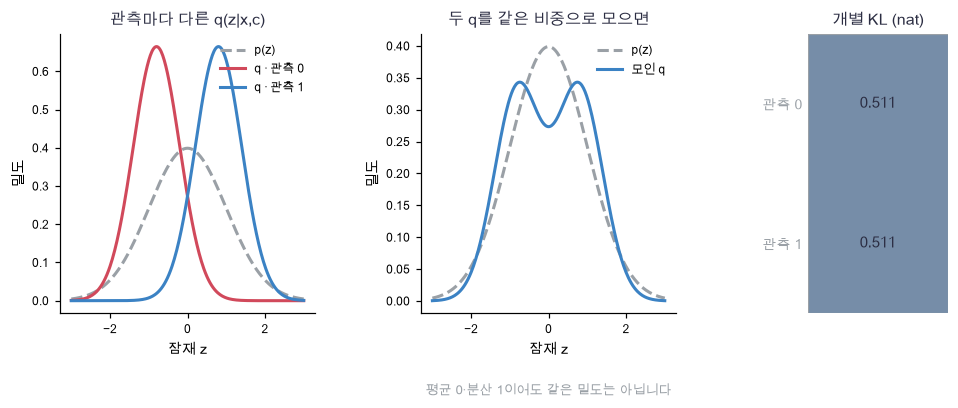

In [3]:
plot_distribution_roles(q_grid, prior_density, q_density, aggregate_density, kl_direct[:, 0])

🔍 **확인** · 가운데 파란 곡선은 평균·분산이 prior와 같아도 모양이 다릅니다. 오른쪽 값은 **각 관측의 q와 prior 사이 KL**입니다. 모인 분포와 prior 사이 KL과 같다고 읽지 않습니다.

조건 c를 고정하면 평균 개별 KL은 $x$와 $z$ 사이의 정보량과 모인 q의 prior 불일치로 분해됩니다. 따라서 평균 KL이 크다는 사실만으로 유용한 정보를 많이 쓴다고 확정할 수도 없습니다. 여기서는 정보량을 추정하지 않고 서로 다른 진단을 나란히 둡니다.

In [4]:
def gaussian_kl(mu, logvar):
    """대각 Gaussian q와 N(0,I)의 KL 성분. 두 (N,L) 배열 → (N,L), 단위 nat."""
    return 0.5 * (mu**2 + np.exp(logvar) - 1.0 - logvar)

In [5]:
# 쓰는 것: q_mu, q_logvar, kl_loop, kl_direct (1절 직접 계산) · gaussian_kl (위 정의)
np.testing.assert_allclose(gaussian_kl(q_mu, q_logvar), kl_loop, atol=1e-14)  # 검산: 벡터화 KL = 반복문
np.testing.assert_allclose(kl_direct[:, 0], [-0.5 * np.log(0.36)] * 2)  # 검산: 두 개별 KL = 손계산
np.testing.assert_allclose(gaussian_kl(np.zeros((3, 2)), np.zeros((3, 2))), 0.0)  # 검산: q=prior이면 KL=0
mixture_mean = q_mu.mean(axis=0)
mixture_variance = (np.exp(q_logvar) + q_mu**2).mean(axis=0) - mixture_mean**2
np.testing.assert_allclose(mixture_mean, 0.0, atol=1e-14)  # 검산: 혼합 평균=0
np.testing.assert_allclose(mixture_variance, 1.0, atol=1e-14)  # 검산: 혼합 분산=1
print("개별 KL의 손계산·반복문·벡터화와 혼합 모멘트 항등식 통과")

개별 KL의 손계산·반복문·벡터화와 혼합 모멘트 항등식 통과


### ✏️ 연습 1 · 잠재 축은 합하고 관측 축은 평균합니다

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

`kl_parts:(N,L)`를 관측 한 개당 KL 한 숫자로 줄이세요.

In [6]:
def exercise_kl_axes(kl_parts):
    """관측당 KL: 잠재 성분 합의 관측 평균입니다."""
    ### 구현할 내용: 잠재 축 합 → 관측 축 평균
    raise NotImplementedError
    return value

In [7]:
# 쓰는 것: run_check (준비 셀) · exercise_kl_axes (바로 위)
def check_kl_axes(fn):
    """작은 독립 손계산으로 연습의 주장을 확인합니다."""
    actual = fn(np.array([[1.0, 2.0], [3.0, 6.0]]))
    np.testing.assert_allclose(actual, 6.0)  # 검산: (3+9)/2=6
    print("잠재 합·관측 평균 통과")

run_check(check_kl_axes, exercise_kl_axes, hint='axis=1 합 뒤 mean입니다.')

☐ exercise_kl_axes: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: axis=1 합 뒤 mean입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = kl_parts.sum(axis=1).mean()
```

</details>

## 🔑 2. β와 warmup은 무엇을 바꾸는지 적습니다

**이 절에서 가져갈 것:** β는 KL의 기여를 바꾸며, warmup은 그 계수를 학습 시간에 따라 바꿉니다. 공통 평가는 항상 $R+K$로 남깁니다.

과일을 비슷하게 복원하는 일과 잠재 분포를 prior에 가깝게 두는 일의 비중을 조절하고 싶습니다. 먼저 이미 정한 복원값에 β만 바꾸어 어떤 항이 달라지는지 봅니다.

> **용어**
>
> - **재구성 항(reconstruction term) $R$**: q에서 뽑은 잠재가 원래 관측에 주는 음의 로그 밀도의 기대값입니다. 좌표별 제곱오차만이 아니라 고정 Gaussian 상수도 포함합니다.
> - **ELBO**: 모델의 관측 로그 밀도보다 작거나 같은 변분 하한입니다. 여기서는 조건부 $\log p_\theta(x\mid c)$의 하한입니다.
> - **β 가중치**: KL에 곱하는 0 이상의 계수입니다. β를 바꾸면 학습 목적이 달라집니다.
> - **KL warmup**: 학습 초기에 KL 계수를 작게 두고 정해진 속도로 올리는 규칙입니다. 여기서는 **annealing**이라는 점진적 계수 변경의 한 형태입니다.

$$R=\mathbb E_q\left[\sum_{d=1}^2\left\{\tfrac12\log(2\pi s^2)
+\frac{(x_d-m_d(z,c))^2}{2s^2}\right\}\right],\qquad
\mathcal J_\beta=R+\beta K.$$

밀도는 1보다 클 수 있어서 연속 Gaussian의 $R$은 음수일 수도 있습니다. 구현은 좌표 둘을 합하고 관측을 평균합니다. β=1일 때 $\mathcal J_1=-\mathrm{ELBO}$입니다. β≠1의 목적은 통상의 ELBO와 다릅니다. 다만 β≥1이면 $-\mathcal J_\beta=\mathrm{ELBO}-(\beta-1)K\le\mathrm{ELBO}$여서 **정확한 기대값**에서는 더 느슨한 하한입니다. 0≤β<1에는 일반적인 하한 보장이 없습니다. 유한 Monte Carlo 추정치의 표본별 하한을 보장하는 설명도 아닙니다.

0부터 세는 갱신 번호 $t$에서 $\beta_t=\beta_\star\min(t/T_w,1)$로 정합니다. $T_w=0$이면 첫 갱신부터 $\beta_\star$입니다. 아래 실험은 β=0·1·4와 $T_w=200,\beta_\star=1$을 **각각 400회** 갱신합니다. β=0에서도 q 샘플의 잡음은 남으므로 결정론적 autoencoder와 같은 계산은 아닙니다.

> **코드**
>
> - `np.stack([a,b])`: 같은 모양 배열을 새 축으로 쌓습니다. 여기서는 규칙 4개를 `(4,401)`에 담습니다.
> - `np.column_stack([a,b])`: 길이가 같은 배열들을 열로 붙입니다.

In [8]:
beta_names = ['β=0', 'β=1', 'β=4', 'warmup→1']
beta_steps = np.arange(401)
beta_schedules = np.stack([np.zeros(401), np.ones(401), np.full(401, 4.0), np.minimum(beta_steps / 200, 1.0)])
fixed_reconstruction = 2.0
fixed_kl = 0.5
beta_weights = np.array([0.0, 1.0, 4.0])
weighted_terms = np.column_stack([np.full(3, fixed_reconstruction), beta_weights * fixed_kl,
                                  fixed_reconstruction + beta_weights * fixed_kl])

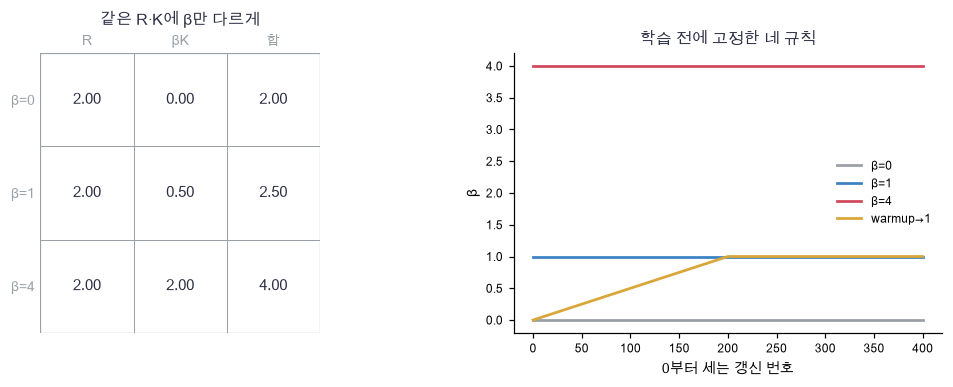

In [9]:
plot_beta_schedule(beta_steps, beta_schedules, beta_names, weighted_terms)

🔍 **확인** · 왼쪽은 같은 R·K에 가중치만 붙인 산술입니다. 오른쪽 warmup은 0에서 출발해 200번 갱신 번호부터 1입니다. 실제 학습 후의 R·K는 모두 변할 수 있습니다. 큰 β가 항상 특정 축을 없애거나 warmup이 항상 더 좋은 해에 도달한다는 보장은 없습니다.

In [10]:
def gaussian_nll(x, mean, observation_sd):
    """고정 s의 Gaussian −log p(x|z,c). (N,D) 두 배열 → 좌표합 (N,)."""
    terms = 0.5 * np.log(2.0 * np.pi * observation_sd**2)
    terms = terms + (x - mean)**2 / (2.0 * observation_sd**2)
    return terms.sum(axis=1)

In [11]:
def beta_at(step, target_beta, warmup_steps):
    """0부터 세는 갱신 step의 KL 계수. warmup=0이면 항상 target_beta입니다."""
    if warmup_steps == 0:
        return float(target_beta)
    return float(target_beta * min(step / warmup_steps, 1.0))

In [12]:
# 쓰는 것: gaussian_nll, beta_at (2절 정의)
hand_x = np.array([[0.0, 2.0], [1.0, -1.0]])
hand_m = np.zeros_like(hand_x)
hand_nll = np.log(2.0 * np.pi) + np.array([2.0, 1.0])
np.testing.assert_allclose(gaussian_nll(hand_x, hand_m, 1.0), hand_nll)  # 검산: Gaussian 상수 + 좌표별 제곱합/2
assert beta_at(0, 1.0, 200) == 0.0, "warmup 첫 계수는 0이어야 합니다"
assert beta_at(100, 1.0, 200) == 0.5, "중간 계수는 0.5이어야 합니다"
assert beta_at(200, 1.0, 200) == 1.0, "경계에서 목표 계수여야 합니다"
assert beta_at(300, 1.0, 200) == 1.0, "경계 뒤에도 목표 계수여야 합니다"
assert beta_at(0, 4.0, 0) == 4.0, "warmup이 없으면 첫 계수부터 목표값이어야 합니다"
print("Gaussian NLL 손계산·warmup 시작/경계/고정 규칙 통과")

Gaussian NLL 손계산·warmup 시작/경계/고정 규칙 통과


### ✏️ 연습 2 · 같은 두 항을 다른 목적에 넣습니다

β가 달라도 공통 −ELBO 평가는 β=1을 씁니다. 두 숫자를 함께 반환하세요.

In [13]:
def exercise_beta_objectives(reconstruction, kl, beta):
    """학습 목적과 공통 음의 ELBO를 반환합니다."""
    ### 구현할 내용: β 학습 목적, β=1 공통 평가
    raise NotImplementedError
    return training, negative_elbo

In [14]:
# 쓰는 것: run_check (준비 셀) · exercise_beta_objectives (바로 위)
def check_beta_objectives(fn):
    """작은 독립 손계산으로 연습의 주장을 확인합니다."""
    actual = fn(2.0, 0.5, 4.0)
    np.testing.assert_allclose(actual, [4.0, 2.5])  # 검산: 2+4×0.5=4, 2+0.5=2.5
    print("학습 목적과 공통 평가 분리 통과")

run_check(check_beta_objectives, exercise_beta_objectives, hint='학습에만 beta를 곱합니다.')

☐ exercise_beta_objectives: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 학습에만 beta를 곱합니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
training = reconstruction + beta * kl
negative_elbo = reconstruction + kl
```

</details>

## 🔑 3. 조건을 두 경로에 넣고 전체 기울기를 검산합니다

**이 절에서 가져갈 것:** 조건 c는 encoder·decoder 양쪽에 들어가며, 관측 입력의 기울기는 encoder 경로와 복원 정답 경로를 모두 더합니다.

같은 붉기·무게라도 품종 정보가 다르면 잠재 해석이나 복원 평균이 달라질 수 있습니다. 조건을 이름표로 출력에만 붙이지 않고, 실제 신경망 입력 열로 넣겠습니다.

$$H_e=\tanh([X,C]W_e+b_e),\quad \mu=H_eW_\mu+b_\mu,\quad
\ell=H_eW_\ell+b_\ell,\quad Z=\mu+e^{\ell/2}\odot\epsilon,$$
$$H_d=\tanh([Z,C]W_d+b_d),\qquad m=H_dW_o+b_o.$$

`[X,C]`는 열을 붙인 `(N,4)`이고 $W_e:(4,H)$입니다. $W_\mu,W_\ell:(H,L)$, `[Z,C]:(N,L+2)`, $W_d:(L+2,H)$, $W_o:(H,2)$입니다. 각 편향은 해당 출력 열 수입니다. **조건은 관측한 입력이며 따로 예측하는 라벨 손실은 없습니다.**

먼저 은닉 폭 2인 고정 배열로 같은 관측·같은 ε, 다른 조건 두 행을 계산합니다. 다음 구현이 이 값과 같은지 검산합니다.

> **용어**
>
> - **tanh**: 입력을 −1과 1 사이로 보내는 매끄러운 활성화 함수입니다. 출력 h를 알고 있으면 도함수는 $1-h^2$입니다.
> - **재매개화**: q에서 직접 뽑는 대신 표준정규 ε와 미분 가능한 μ·σ를 결합해 $z=\mu+\sigma\epsilon$로 쓰는 것입니다.
>
> **코드** · `np.concatenate([x,c], axis=1)`은 관측 행은 유지하고 두 배열의 열을 이어 붙입니다. `p['We']`는 이름에 대응하는 가중치 배열을 꺼냅니다.

> **코드**
>
> - `np.ndindex(array.shape)`는 배열의 모든 좌표를 차례대로 줍니다. 하나씩 ±h를 더한 뒤 반드시 원래 값을 복구합니다.
> - `for name in p`는 사전에 저장된 파라미터 이름들을 순회합니다. `p[name].copy()`는 원본과 메모리를 공유하지 않는 복사본입니다.

In [15]:
flow_x = np.array([[0.2, -0.3], [0.2, -0.3]])
flow_c = np.eye(2)
flow_eps = np.array([[0.5, -0.2], [0.5, -0.2]])
flow_we = np.array([[0.2, 0.1], [-0.3, 0.2], [0.4, -0.2], [-0.1, 0.5]])
flow_wd = np.array([[0.5, -0.2], [0.1, 0.4], [0.5, 0.0], [-0.5, 0.2]])
flow_joined = np.concatenate([flow_x, flow_c], axis=1)
flow_h = np.tanh(flow_joined @ flow_we)
flow_mu = flow_h * 0.3
flow_lv = flow_h * -0.2
flow_sd = np.exp(0.5 * flow_lv)
flow_z = flow_mu + flow_sd * flow_eps
flow_dec_joined = np.concatenate([flow_z, flow_c], axis=1)
flow_m = np.tanh(flow_dec_joined @ flow_wd)
flow_mu_sd = np.concatenate([flow_mu, flow_sd], axis=1)

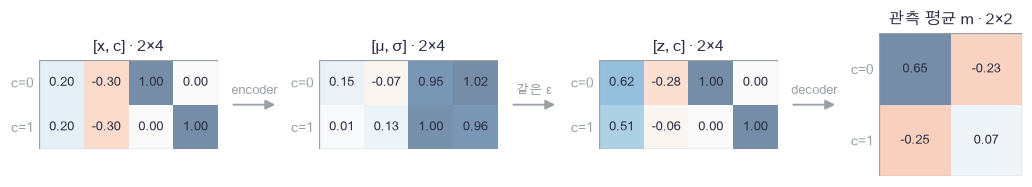

In [16]:
plot_conditional_flow(flow_joined, flow_mu_sd, flow_dec_joined, flow_m)

🔍 **확인** · 왼쪽 두 행에서 바꾼 것은 조건 두 열뿐입니다. 가운데 z에도, 마지막 평균에도 조건의 영향이 들어갑니다. 이 고정 예의 차이가 모든 학습 모델에서 같은 크기라는 뜻은 아닙니다.

In [17]:
def init_cvae(seed, hidden=12, latent=2, conditions=2):
    """2차원 관측용 조건부 VAE의 10개 파라미터 배열을 새로 만듭니다."""
    rng = np.random.default_rng(seed)
    p = {}
    p['We'] = rng.normal(0.0, 0.35, (2 + conditions, hidden))
    p['be'] = np.zeros(hidden)
    p['Wmu'] = rng.normal(0.0, 0.15, (hidden, latent))
    p['bmu'] = np.zeros(latent)
    p['Wlv'] = rng.normal(0.0, 0.08, (hidden, latent))
    p['blv'] = np.zeros(latent)
    p['Wd'] = rng.normal(0.0, 0.35, (latent + conditions, hidden))
    p['bd'] = np.zeros(hidden)
    p['Wo'] = rng.normal(0.0, 0.25, (hidden, 2))
    p['bo'] = np.zeros(2)
    return p

In [18]:
def encode_cvae(x, condition, p):
    """[x,c] → tanh → (μ,logσ²). x:(N,2), c:(N,C) → 두 (N,L)와 cache."""
    joined = np.concatenate([x, condition], axis=1)
    hidden = np.tanh(joined @ p['We'] + p['be'])
    mu = hidden @ p['Wmu'] + p['bmu']
    logvar = hidden @ p['Wlv'] + p['blv']
    return mu, logvar, (joined, hidden)

In [19]:
def decode_cvae(z, condition, p):
    """[z,c] → tanh → Gaussian 관측 평균 m. z:(N,L), c:(N,C) → m:(N,2), cache."""
    joined = np.concatenate([z, condition], axis=1)
    hidden = np.tanh(joined @ p['Wd'] + p['bd'])
    mean = hidden @ p['Wo'] + p['bo']
    return mean, (joined, hidden)

In [20]:
def cvae_forward(x, condition, eps, p):
    """고정 ε:(N,L)로 재매개화한 전 경로. 관측 평균과 역전파용 중간값을 반환합니다."""
    # 쓰는 것: encode_cvae, decode_cvae (3절 정의)
    mu, logvar, encoder_cache = encode_cvae(x, condition, p)
    sd = np.exp(0.5 * logvar)
    z = mu + sd * eps
    mean, decoder_cache = decode_cvae(z, condition, p)
    cache = (mu, logvar, sd, encoder_cache, decoder_cache)
    return mean, cache

In [21]:
# 쓰는 것: flow_we, flow_wd, flow_x, flow_c, flow_eps, flow_m (3절 직접 계산) · cvae_forward (위 정의)
flow_p = {'We': flow_we.copy(), 'be': np.zeros(2), 'Wmu': 0.3 * np.eye(2), 'bmu': np.zeros(2),
          'Wlv': -0.2 * np.eye(2), 'blv': np.zeros(2), 'Wd': flow_wd.copy(), 'bd': np.zeros(2),
          'Wo': np.eye(2), 'bo': np.zeros(2)}
implemented_m, implemented_cache = cvae_forward(flow_x, flow_c, flow_eps, flow_p)
np.testing.assert_allclose(implemented_m, flow_m, atol=1e-14)  # 검산: 함수의 조건부 전 경로 = 직접 계산
print("조건을 encoder·decoder에 넣는 직접 계산과 구현 일치")

조건을 encoder·decoder에 넣는 직접 계산과 구현 일치


In [22]:
# 쓰는 것: flow_p, flow_x, flow_c, flow_eps, flow_m (3절 직접 계산) · cvae_forward (3절 정의)
no_condition_p = {}
for name in flow_p:
    no_condition_p[name] = flow_p[name].copy()
no_condition_p['We'][2:] = 0.0
no_condition_p['Wd'][2:] = 0.0
no_condition_m, no_condition_cache = cvae_forward(flow_x, flow_c, flow_eps, no_condition_p)
np.testing.assert_allclose(no_condition_m[0], no_condition_m[1])  # 검산: 두 조건 경로를 끊으면 같은 x·ε의 평균은 같음
assert np.max(np.abs(flow_m[0] - flow_m[1])) > 0.1, "고정 손계산 예에서는 조건 열이 실제 평균을 바꿔야 합니다"
print("고정 예의 조건 경로 존재·두 경로 차단 통과")

고정 예의 조건 경로 존재·두 경로 차단 통과


📎 **역전파의 두 갈래** · 고정 ε에서 $G_m=(m-X)/(Ns^2)$입니다. decoder를 거쳐 돌아온 $G_z$에 KL의 기여를 더합니다.

$$G_\mu=G_z+\beta\mu/N,\qquad
G_\ell=\tfrac12G_z\odot e^{\ell/2}\odot\epsilon
+\frac{\beta}{2N}(e^\ell-1).$$

각 아핀 층은 $G_W=H^\top G$, $G_b=\sum_nG_n$이고, tanh에는 $1-H^2$를 곱합니다. encoder에서 돌아온 `dinput`을 얻으면

$$G_X=G_{X,encoder}-G_m,\qquad G_C=G_{C,encoder}+G_{C,decoder}.$$

$-G_m$은 X가 복원 **정답**으로도 들어간 직접 경로입니다. 학습에서는 X·C를 갱신하지 않지만, 이 경로까지 중심차분으로 확인하면 모델 전체 연결을 검사할 수 있습니다. 조건 기울기는 one-hot 선택 자체의 미분이 아니라 **조건 벡터를 연속 입력으로 잠깐 완화한 함수**의 미분입니다.

In [23]:
def cvae_loss_grad(x, condition, eps, p, beta, observation_sd):
    """R+βK의 고정 ε 역전파. loss, 모든 파라미터 기울기, dx:(N,2), dc:(N,C)를 반환합니다."""
    # 쓰는 것: cvae_forward (3절), gaussian_nll, gaussian_kl (1–2절)
    # 1. 전 경로와 표본 평균 목적
    mean, cache = cvae_forward(x, condition, eps, p)
    mu, logvar, sd, encoder_cache, decoder_cache = cache
    enc_joined, enc_hidden = encoder_cache
    dec_joined, dec_hidden = decoder_cache
    n, latent = mu.shape
    loss = np.mean(gaussian_nll(x, mean, observation_sd))
    loss = loss + beta * np.mean(gaussian_kl(mu, logvar).sum(axis=1))
    # 2. decoder: m → tanh → [z,c]
    dm = (mean - x) / (n * observation_sd**2)
    grad = {}
    grad['Wo'] = dec_hidden.T @ dm
    grad['bo'] = dm.sum(axis=0)
    da = (dm @ p['Wo'].T) * (1.0 - dec_hidden**2)
    grad['Wd'] = dec_joined.T @ da
    grad['bd'] = da.sum(axis=0)
    djoined = da @ p['Wd'].T
    dz = djoined[:, :latent]
    dc = djoined[:, latent:].copy()
    # 3. 재매개화 경로와 KL 경로를 합합니다.
    dmu = dz + beta * mu / n
    dlv = dz * sd * eps * 0.5 + beta * (np.exp(logvar) - 1.0) / (2.0 * n)
    grad['Wmu'] = enc_hidden.T @ dmu
    grad['bmu'] = dmu.sum(axis=0)
    grad['Wlv'] = enc_hidden.T @ dlv
    grad['blv'] = dlv.sum(axis=0)
    # 4. encoder: 두 출력의 기여 → tanh → [x,c]
    dh = dmu @ p['Wmu'].T + dlv @ p['Wlv'].T
    de = dh * (1.0 - enc_hidden**2)
    grad['We'] = enc_joined.T @ de
    grad['be'] = de.sum(axis=0)
    dinput = de @ p['We'].T
    dx = dinput[:, :2] - dm
    dc = dc + dinput[:, 2:]
    return float(loss), grad, dx, dc

In [24]:
def finite_difference(array, objective, step=1e-5):
    """배열의 모든 원소를 하나씩 ±step 이동한 중심차분. 원래 값을 복구합니다."""
    result = np.zeros_like(array)
    for index in np.ndindex(array.shape):
        old = array[index]
        array[index] = old + step
        plus = objective()
        array[index] = old - step
        minus = objective()
        array[index] = old
        result[index] = (plus - minus) / (2.0 * step)
    return result

📎 **검산 범위** · 모든 파라미터 원소·X·C를 중심차분합니다. ε는 양쪽 평가에서 고정합니다. 이는 한 번 뽑힌 표본 목적의 미분 검산이며, 기대값과 미분의 교환 자체를 증명하지 않습니다([27번](27_monte_carlo_gradients.ipynb)). β=0·1·4의 계수 선형성도 별도로 검사합니다.

In [25]:
def check_cvae_gradients():
    """작은 조건부 VAE에서 10개 파라미터 배열·X·연속 C의 전체 중심차분을 확인합니다."""
    # 쓰는 것: init_cvae, cvae_loss_grad, finite_difference, beta_at (2–3절)
    p = init_cvae(260, hidden=3)
    x = np.array([[0.2, -0.4], [-0.1, 0.3]])
    condition = np.eye(2)
    eps = np.array([[0.5, -0.3], [-0.2, 0.7]])
    def objective():
        """같은 ε를 고정한 β=0.7 표본 목적 한 숫자입니다."""
        return cvae_loss_grad(x, condition, eps, p, 0.7, 0.4)[0]
    loss, grad, dx, dc = cvae_loss_grad(x, condition, eps, p, 0.7, 0.4)
    errors = []
    for name in p:
        numeric = finite_difference(p[name], objective)
        np.testing.assert_allclose(grad[name], numeric, atol=2e-7, rtol=2e-5)  # 검산: 모든 파라미터의 분석 미분 = 중심차분
        errors.append(np.max(np.abs(grad[name] - numeric)))
    for array, analytic in [(x, dx), (condition, dc)]:
        numeric = finite_difference(array, objective)
        np.testing.assert_allclose(analytic, numeric, atol=2e-7, rtol=2e-5)  # 검산: 입력의 모든 경로 미분 = 중심차분
        errors.append(np.max(np.abs(analytic - numeric)))
    print("전체 파라미터·관측·조건 중심차분 최대 절대오차:", max(errors))

In [26]:
# 쓰는 것: check_cvae_gradients (바로 위)
check_cvae_gradients()

전체 파라미터·관측·조건 중심차분 최대 절대오차: 6.0083715780479e-11


In [27]:
def check_beta_paths():
    """β=0·1·4의 목적/기울기 선형성, warmup 계수 0, 조건 양쪽 경로를 확인합니다."""
    # 쓰는 것: init_cvae, cvae_loss_grad, beta_at (2–3절)
    p = init_cvae(261, hidden=3)
    x = np.array([[0.2, -0.4], [-0.1, 0.3]])
    c = np.eye(2)
    eps = np.array([[0.5, -0.3], [-0.2, 0.7]])
    zero = cvae_loss_grad(x, c, eps, p, 0.0, 0.4)
    one = cvae_loss_grad(x, c, eps, p, 1.0, 0.4)
    four = cvae_loss_grad(x, c, eps, p, 4.0, 0.4)
    np.testing.assert_allclose(four[0], zero[0] + 4 * (one[0] - zero[0]))  # 검산: 목적의 β 선형성
    for name in p:
        np.testing.assert_allclose(four[1][name], zero[1][name] + 4 * (one[1][name] - zero[1][name]), atol=1e-14)  # 검산: 파라미터 기울기의 β 선형성
    warm = cvae_loss_grad(x, c, eps, p, beta_at(0, 1.0, 200), 0.4)
    for position in [2, 3]:
        np.testing.assert_allclose(four[position], zero[position] + 4 * (one[position] - zero[position]), atol=1e-14)  # 검산: 관측·조건 입력 기울기의 β 선형성
    np.testing.assert_allclose(warm[0], zero[0])  # 검산: warmup 첫 목적 = β0 목적
    for name in p:
        np.testing.assert_allclose(warm[1][name], zero[1][name])  # 검산: warmup 첫 기울기 = β0 기울기
    print("β=0·1·4 및 warmup 계수 0의 정확한 대수 관계 통과")

In [28]:
# 쓰는 것: check_beta_paths (바로 위)
check_beta_paths()

β=0·1·4 및 warmup 계수 0의 정확한 대수 관계 통과


### ✏️ 연습 3 · 재매개화와 KL의 기여를 더합니다

`dz`, `sd`, `eps`, `logvar`가 모두 `(N,L)`일 때 log 분산의 기울기를 완성하세요.

In [29]:
def exercise_logvar_grad(dz, sd, eps, logvar, beta):
    """평균 목적의 log 분산 기울기 두 항을 더합니다."""
    n = len(dz)
    ### 구현할 내용: 샘플 경로 + β KL 경로
    raise NotImplementedError
    return gradient

In [30]:
# 쓰는 것: run_check (준비 셀) · exercise_logvar_grad (바로 위)
def check_logvar_grad(fn):
    """작은 독립 손계산으로 연습의 주장을 확인합니다."""
    actual = fn(np.array([[2.0]]), np.array([[2.0]]), np.array([[0.5]]), np.array([[np.log(4.0)]]), 0.4)
    np.testing.assert_allclose(actual, [[1.6]])  # 검산: 2×2×0.5/2 + 0.4×3/2 = 1.6
    print("재매개화와 KL 기울기 합 통과")

run_check(check_logvar_grad, exercise_logvar_grad, hint='두 항의 1/2와 관측 평균 1/N 위치를 구분하세요.')

☐ exercise_logvar_grad: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 두 항의 1/2와 관측 평균 1/N 위치를 구분하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = 0.5 * dz * sd * eps + beta * (np.exp(logvar) - 1.0) / (2.0 * n)
```

</details>

## 🔑 4. 같은 예산으로 학습하고 고정 잡음으로 평가합니다

**이 절에서 가져갈 것:** 학습 목적이 달라도 공통 test에서 R·KL·−ELBO를 비교하고, 평가 잡음의 SE와 학습 seed 간 SD를 구분합니다.

한 품종의 붉기와 무게가 곡선 모양으로 함께 변하도록 자료를 만듭니다. 숨은 숫자 $t\sim\mathcal N(0,1)$, 품종 번호 $a\in\{0,1\}$와 $u=2a-1$을 써서

$$x_0=1.25u+0.65t+\xi_0,\qquad
x_1=0.55(t^2-1)+0.20u+\xi_1,\qquad \xi_d\sim\mathcal N(0,0.12^2).$$

자료 생성의 $t$는 학습에 주지 않습니다. 모델의 관측 표준편차는 $s=0.25$이며 자료 잡음 0.12와 다릅니다. 이는 일부러 고정한 작은 근사 모델입니다. train 512개, valid 192개, test 256개는 서로 다른 난수열로 독립 생성하며, 전처리나 test를 이용한 설정 선택은 없습니다.

> **용어**
>
> - **train·valid·test**: 각각 가중치 학습, 학습 과정 점검, 마지막 독립 평가에 쓰는 관측입니다. 여기서는 valid로 최적 checkpoint를 고르지 않고 모든 후보의 마지막 400회 갱신을 평가합니다.
> - **미니배치**: 한 번 갱신에 쓰는 관측 묶음입니다. 여기서는 train 번호를 복원추출해 64개씩 씁니다.
> - **Monte Carlo(MC) 표준오차 SE**: 데이터와 모델을 고정하고 잠재 잡음만 다시 뽑을 때 평균 추정값의 흔들림을 나타냅니다. 재학습 변동이나 새 test 표본의 변동은 포함하지 않습니다.
> - **표준편차 SD**: 여기서는 3개 학습 seed에서 얻은 최종 점수 자체의 흩어짐입니다. seed 평균의 표준오차나 신뢰구간으로 부르지 않습니다.

$$R_k=\frac1N\sum_n-\log p_\theta(x_n\mid \mu_n+\sigma_n\epsilon_{kn},c_n),\quad
\widehat{-\mathrm{ELBO}}=\frac1K\sum_k R_k+\bar K,\quad
\widehat{\mathrm{SE}}_{MC}=\frac{\operatorname{std}(R_1,\ldots,R_K;\mathrm{ddof}=1)}{\sqrt K}.$$

평가 ε의 shape는 `(K,N,L)`입니다. **k마다 N개 관측의 잠재 난수를 새로 독립 추출**합니다. 한번 만든 bank를 모든 후보가 공유하면 차이를 짝지어 비교할 수 있습니다. 같은 bank를 재사용한 값들을 독립 반복으로 세지는 않습니다.

아래의 작은 계산은 평가 축만 읽기 위한 예입니다. $\mu=X$, $\sigma=0.2$, $m=Z$로 직접 정하고, 학습은 하지 않습니다. 실제 학습 자료와 모델은 그 뒤에서 별도로 만듭니다.

> **코드** · `rng.normal(size=(K,N,L))`은 지정한 모양의 표준정규 난수를 만듭니다. `std(ddof=1)`은 독립 반복 K개의 표본 분산 분모를 K−1로 둡니다.

In [31]:
# 쓰는 것: gaussian_nll (2절)
eval_example_train = np.array([[-1.0, -0.4], [-0.8, 0.2], [0.9, -0.3], [1.4, 0.6]])
eval_example_valid = np.array([[-1.2, 0.1], [-0.6, -0.3], [1.1, -0.2], [1.5, 0.3]])
eval_example_eps = np.random.default_rng(2600).normal(size=(4, 4, 2))
eval_example_r = []
for eps in eval_example_eps:
    example_mean = eval_example_valid + 0.2 * eps
    eval_example_r.append(gaussian_nll(eval_example_valid, example_mean, 0.25).mean())
eval_example_r = np.array(eval_example_r)

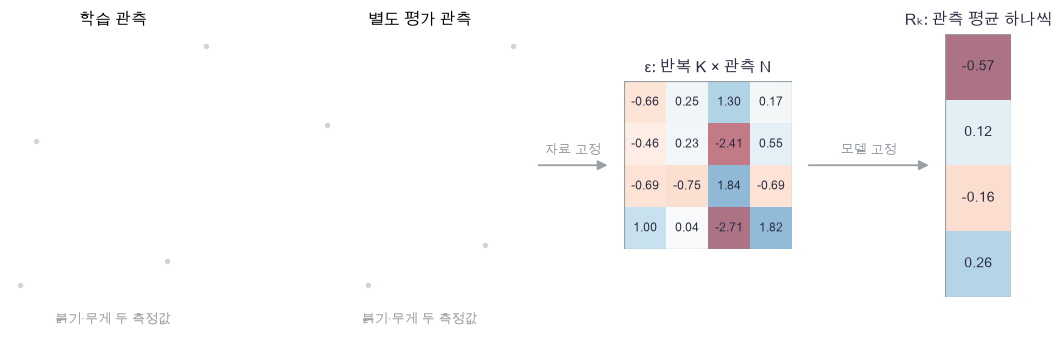

In [32]:
plot_evaluation_flow(eval_example_train, eval_example_valid, eval_example_eps[:, :, 0], eval_example_r)

🔍 **확인** · ε 표의 한 행은 전체 평가 관측에 대한 한 번의 독립 잠재 추출입니다. 마지막 판에는 관측 축을 평균한 숫자 하나가 남습니다. 여러 관측의 손실 SD를 그대로 K의 SE로 쓰지 않습니다.

실험에서는 같은 seed끼리 초기값·배치 번호·학습 ε 순서가 완전히 같습니다. β 규칙만 달리해 갱신 경로를 비교합니다. seed 261·262·263은 모두 보고합니다. 서로 다른 seed에도 train/valid/test와 평가 ε는 고정되어 있으므로, seed SD는 **이 고정 자료에 조건부인 학습 난수 변동**입니다.

> **코드**
>
> - `rng.integers(0,N,size=B)`는 0부터 N−1까지 번호를 B개 복원추출합니다. 같은 관측이 배치에 두 번 들어갈 수 있습니다.
> - `np.eye(2)[labels]`는 품종 번호를 one-hot 행으로 바꿉니다.
> - `score['kl']`은 지표 사전에서 이름으로 값을 꺼냅니다. 중간값인 `encoder_cache` 등을 받아도 평가에서 사용하지 않는 경우가 있습니다.

In [33]:
def make_fruit_data(seed, size):
    """조건별 휘어진 2차원 과일 측정값. 독립 t·관측잡음으로 x:(N,2), c:(N,2)를 만듭니다."""
    rng = np.random.default_rng(seed)
    labels = rng.integers(0, 2, size=size)
    signed = 2.0 * labels - 1.0
    t = rng.normal(size=size)
    x = np.column_stack([1.25 * signed + 0.65 * t,
                         0.55 * (t**2 - 1.0) + 0.20 * signed])
    x = x + rng.normal(0.0, 0.12, size=x.shape)
    condition = np.eye(2)[labels]
    return x, condition

In [34]:
def evaluate_cvae(x, condition, p, eps_bank, observation_sd):
    """고정 데이터·모델에서 K개 독립 ε 묶음의 R와 정확한 KL. ε:(K,N,L), R:(K,)."""
    # 쓰는 것: encode_cvae, decode_cvae, gaussian_nll, gaussian_kl (1–3절)
    mu, logvar, encoder_cache = encode_cvae(x, condition, p)
    sd = np.exp(0.5 * logvar)
    recon_draws = []
    for eps in eps_bank:
        mean, decoder_cache = decode_cvae(mu + sd * eps, condition, p)
        recon_draws.append(gaussian_nll(x, mean, observation_sd).mean())
    recon_draws = np.array(recon_draws)
    kl_dim = gaussian_kl(mu, logvar).mean(axis=0)
    neg_elbo_draws = recon_draws + kl_dim.sum()
    return {'reconstruction': recon_draws.mean(), 'kl': kl_dim.sum(),
            'negative_elbo': neg_elbo_draws.mean(), 'draws': neg_elbo_draws,
            'mc_se': neg_elbo_draws.std(ddof=1) / np.sqrt(len(eps_bank)),
            'kl_dim': kl_dim, 'mu': mu, 'logvar': logvar}

In [35]:
# 쓰는 것: init_cvae, evaluate_cvae, gaussian_nll (2–4절)
constant_p = init_cvae(2608, hidden=3)
for name in ['Wmu', 'bmu', 'Wlv', 'blv', 'Wo']:
    constant_p[name] = np.zeros_like(constant_p[name])
constant_p['bo'] = np.array([0.2, -0.3])
constant_x = np.array([[0.0, 0.0], [0.5, 0.2]])
constant_eps = np.random.default_rng(2609).normal(size=(5, 2, 2))
constant_score = evaluate_cvae(constant_x, np.eye(2), constant_p, constant_eps, 0.25)
constant_expected = np.mean(np.log(2 * np.pi * 0.25**2) + ((constant_x - constant_p['bo'])**2).sum(axis=1) / (2 * 0.25**2))
np.testing.assert_allclose(constant_score['negative_elbo'], constant_expected)  # 검산: q=prior·상수 decoder의 −ELBO = 닫힌식 NLL
np.testing.assert_allclose(constant_score['kl'], 0.0)  # 검산: q=prior이면 KL=0
np.testing.assert_allclose(constant_score['mc_se'], 0.0, atol=1e-14)  # 검산: z에 무관한 decoder의 MC 흔들림=0
print("MC 평가의 상수 decoder 독립 닫힌식 검산 통과")

MC 평가의 상수 decoder 독립 닫힌식 검산 통과


📎 **갱신식도 본문에 둡니다** · $g_t$는 한 미니배치에서 얻은 모든 파라미터의 기울기입니다. Adam은 각 원소에 대해

$$a_t=0.9a_{t-1}+0.1g_t,\quad v_t=0.999v_{t-1}+0.001g_t^2,\quad
\theta_t=\theta_{t-1}-0.005\frac{a_t/(1-0.9^t)}{\sqrt{v_t/(1-0.999^t)}+10^{-8}}$$

로 갱신합니다. Adam의 $t$는 1부터, warmup의 갱신 번호는 0부터 셉니다. 모델 하나는 198개 파라미터를 가지고, 400회×64개=25,600개 관측 제시를 받습니다. 복원추출이므로 서로 다른 25,600개 관측이라는 뜻은 아닙니다.

> **용어** · **Adam**: 기울기의 지수 이동평균과 제곱의 이동평균으로 각 원소의 갱신 폭을 조절하는 optimizer입니다. 초기 0 상태에 대한 편향 보정을 포함합니다.

> **코드** · `sum(value.size for value in p.values())`는 모든 파라미터 배열의 실제 원소 수를 합합니다. `step % 100 == 0`은 100번마다 점검하는 조건입니다. `break`는 마지막 점검 뒤 갱신 없이 반복을 끝냅니다.

In [36]:
def adam_update(p, grad, first, second, step, learning_rate):
    """Adam의 두 모멘트와 편향 보정. step은 1부터 세며 파라미터와 상태를 제자리 갱신합니다."""
    for name in p:
        first[name] = 0.9 * first[name] + 0.1 * grad[name]
        second[name] = 0.999 * second[name] + 0.001 * grad[name]**2
        corrected_first = first[name] / (1.0 - 0.9**step)
        corrected_second = second[name] / (1.0 - 0.999**step)
        p[name] -= learning_rate * corrected_first / (np.sqrt(corrected_second) + 1e-8)

In [37]:
def train_cvae(train_x, train_c, valid_x, valid_c, eval_eps, seed,
               target_beta, warmup_steps, steps=400, batch_size=64, observation_sd=0.25):
    """같은 seed에서 동일 초기값·배치·ε 순서로 지정한 β 규칙만 바꾸어 학습합니다."""
    # 쓰는 것: init_cvae, cvae_loss_grad, beta_at, adam_update, evaluate_cvae (2–4절)
    # 1. 초기 파라미터와 독립 학습 난수열
    p = init_cvae(seed)
    rng = np.random.default_rng(seed + 10000)
    first = {}
    second = {}
    for name in p:
        first[name] = np.zeros_like(p[name])
        second[name] = np.zeros_like(p[name])
    history = []
    # 2. 모든 후보가 매번 같은 수의 배치 번호와 잠재 잡음을 소비합니다.
    for step in range(steps + 1):
        if step % 100 == 0:
            score = evaluate_cvae(valid_x, valid_c, p, eval_eps, observation_sd)
            history.append([step, score['reconstruction'], score['kl'], score['negative_elbo']])
        if step == steps:
            break
        index = rng.integers(0, len(train_x), size=batch_size)
        eps = rng.normal(size=(batch_size, p['bmu'].size))
        beta = beta_at(step, target_beta, warmup_steps)
        loss, grad, dx, dc = cvae_loss_grad(train_x[index], train_c[index], eps, p, beta, observation_sd)
        adam_update(p, grad, first, second, step + 1, 0.005)
    return p, np.array(history)

In [38]:
# 쓰는 것: make_fruit_data (4절) · beta_names (2절)
train_x, train_c = make_fruit_data(2601, 512)
valid_x, valid_c = make_fruit_data(2602, 192)
test_x, test_c = make_fruit_data(2603, 256)
valid_eps = np.random.default_rng(2604).normal(size=(8, len(valid_x), 2))
test_eps = np.random.default_rng(2605).normal(size=(32, len(test_x), 2))
training_seeds = [261, 262, 263]
settings = [(0.0, 0), (1.0, 0), (4.0, 0), (1.0, 200)]
observation_sd = 0.25
print("train/valid/test:", len(train_x), len(valid_x), len(test_x))
print("seed:", training_seeds, "· 후보별 갱신 400 · 배치 64 · 관측 제시 25,600")
print("후보:", beta_names, "· Adam 학습률 0.005 · 평가 ε는 후보 간 공유")

train/valid/test: 512 192 256
seed: [261, 262, 263] · 후보별 갱신 400 · 배치 64 · 관측 제시 25,600
후보: ['β=0', 'β=1', 'β=4', 'warmup→1'] · Adam 학습률 0.005 · 평가 ε는 후보 간 공유


In [39]:
# 쓰는 것: train_cvae, evaluate_cvae (4절) · train_x/c, valid_x/c, test_x/c, valid_eps, test_eps, settings, training_seeds, observation_sd (실험 설정)
all_models = []
all_histories = []
all_scores = []
for target_beta, warmup_steps in settings:
    models = []
    histories = []
    scores = []
    for seed in training_seeds:
        model, history = train_cvae(train_x, train_c, valid_x, valid_c, valid_eps,
                                    seed, target_beta, warmup_steps, observation_sd=observation_sd)
        models.append(model)
        histories.append(history)
        scores.append(evaluate_cvae(test_x, test_c, model, test_eps, observation_sd))
    all_models.append(models)
    all_histories.append(histories)
    all_scores.append(scores)
all_histories = np.array(all_histories)
print("실제 파라미터 수:", sum(value.size for value in all_models[0][0].values()))
print("학습 완료: 후보 4 × seed 3 =", len(all_scores) * len(training_seeds), "개 모델")

실제 파라미터 수: 198
학습 완료: 후보 4 × seed 3 = 12 개 모델


🔍 **학습 과정** · 다음은 valid의 seed 3개 **평균** 곡선입니다. β=0·4로 학습한 모델도 오른쪽에서는 동일한 $R+K$로 평가합니다. 서로 다른 β의 학습 목적값 자체를 성능 순위로 비교하지 않습니다.

`all_histories:(후보,seed,기록시점,열)`의 마지막 열들은 step·R·KL·−ELBO 순서입니다.

In [40]:
# 쓰는 것: all_histories (학습 실행)
history_steps = all_histories[0, 0, :, 0]
history_mean = all_histories[:, :, :, 1:].mean(axis=1)

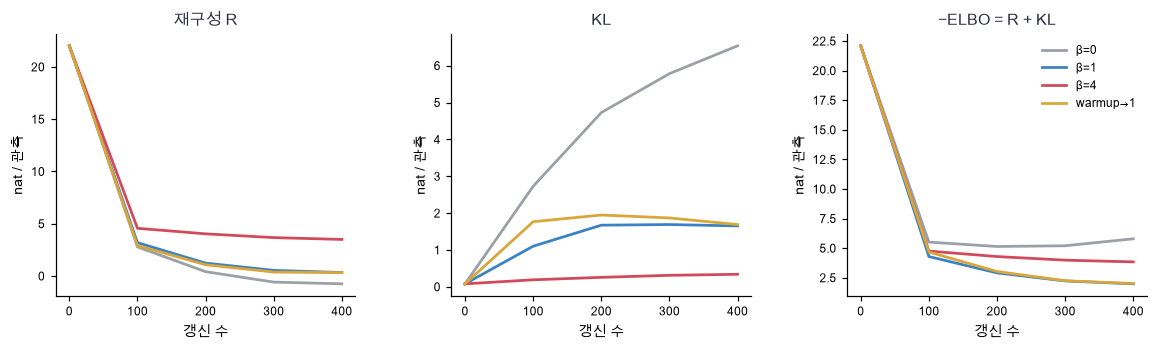

In [41]:
plot_learning(history_steps, history_mean, beta_names)

🔍 **독립 test 평가** · 표의 각 행은 후보 하나의 seed 평균±SD입니다. 그림 오차 막대도 그 SD입니다. 별도로 출력하는 MC SE는 각 학습 모델을 고정한 잠재 평가 잡음의 크기입니다. 두 불확실성을 더해서 하나의 신뢰구간으로 제시하지 않습니다.

같은 평가 ε를 쓴 두 후보 A·B의 차이는 $D_k=(R_{B,k}+K_B)-(R_{A,k}+K_A)$로 짝짓습니다. 차이의 MC SE는 $\operatorname{std}(D_k)/\sqrt K$이며, 독립 후보라고 가정한 두 SE의 제곱합을 쓰지 않습니다.

In [42]:
# 쓰는 것: all_scores, beta_names (학습 결과/설정)
metric_values = np.zeros((4, 3, 3))
mc_standard_errors = np.zeros((4, 3))
for candidate in range(4):
    for repeat in range(3):
        score = all_scores[candidate][repeat]
        metric_values[candidate, repeat] = [score['reconstruction'], score['kl'], score['negative_elbo']]
        mc_standard_errors[candidate, repeat] = score['mc_se']
metric_means = metric_values.mean(axis=1)
metric_sds = metric_values.std(axis=1, ddof=1)
for candidate, name in enumerate(beta_names):
    print(name, "[R, KL, −ELBO] 평균:", np.round(metric_means[candidate], 3), "SD:", np.round(metric_sds[candidate], 3))
    print("  각 seed의 MC SE:", np.round(mc_standard_errors[candidate], 4))

β=0 [R, KL, −ELBO] 평균: [-0.785  6.554  5.769] SD: [0.075 0.227 0.153]
  각 seed의 MC SE: [0.0013 0.0022 0.001 ]
β=1 [R, KL, −ELBO] 평균: [0.281 1.924 2.205] SD: [0.136 0.139 0.054]
  각 seed의 MC SE: [0.0104 0.0109 0.0093]
β=4 [R, KL, −ELBO] 평균: [4.436 0.484 4.92 ] SD: [0.488 0.081 0.408]
  각 seed의 MC SE: [0.0394 0.0274 0.0351]
warmup→1 [R, KL, −ELBO] 평균: [0.274 1.957 2.23 ] SD: [0.12  0.117 0.061]
  각 seed의 MC SE: [0.0104 0.0116 0.0096]


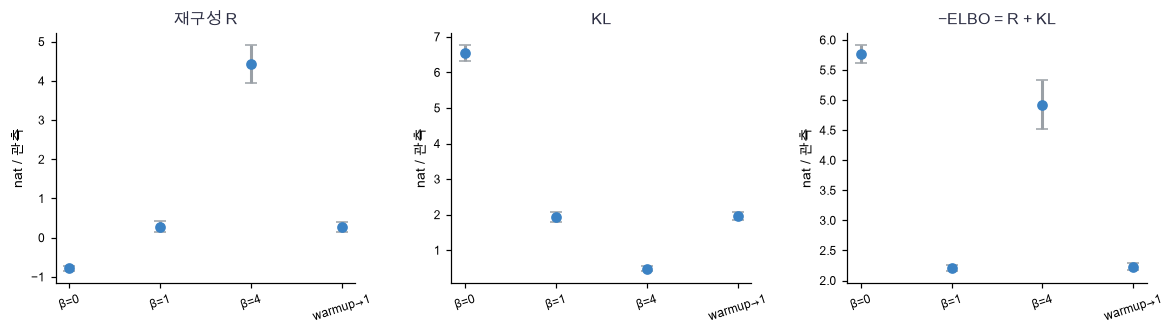

In [43]:
plot_test_metrics(beta_names, metric_means, metric_sds)

In [44]:
# 쓰는 것: all_scores (학습 결과) · test_eps, training_seeds (평가 설정)
for repeat, seed in enumerate(training_seeds):
    paired_draws = all_scores[3][repeat]['draws'] - all_scores[1][repeat]['draws']
    paired_se = paired_draws.std(ddof=1) / np.sqrt(len(test_eps))
    print("seed", seed, "warmup − β1, −ELBO 차이:", round(paired_draws.mean(), 4), "짝지은 MC SE:", round(paired_se, 4))
# 검산은 구조·유한값을 확인합니다. 어느 후보가 더 좋은지는 assert하지 않습니다.
assert np.isfinite(metric_values).all(), "모든 실제 학습의 평가값은 유한해야 합니다"
print("고정 예산 실험의 유한값 검사 통과 · 후보의 우열은 관측 결과입니다")

seed 261 warmup − β1, −ELBO 차이: 0.0287 짝지은 MC SE: 0.0008
seed 262 warmup − β1, −ELBO 차이: 0.0322 짝지은 MC SE: 0.004
seed 263 warmup − β1, −ELBO 차이: 0.0158 짝지은 MC SE: 0.0011
고정 예산 실험의 유한값 검사 통과 · 후보의 우열은 관측 결과입니다


### ✏️ 연습 4 · 공유 잡음의 차이를 짝지어 평가합니다

두 모델이 같은 ε bank를 썼습니다. 반복별 −ELBO 차이의 평균과 MC SE를 구하세요.

In [45]:
def exercise_paired_se(draws_a, draws_b):
    """고정 두 모델의 공유 난수 평가 차이와 그 MC SE입니다."""
    difference = draws_b - draws_a
    ### 구현할 내용: 차이의 평균, K회 평균의 SE
    raise NotImplementedError
    return average, se

In [46]:
# 쓰는 것: run_check (준비 셀) · exercise_paired_se (바로 위)
def check_paired_se(fn):
    """작은 독립 손계산으로 연습의 주장을 확인합니다."""
    actual = fn(np.array([1.0, 10.0, -2.0]), np.array([2.0, 12.0, 1.0]))
    np.testing.assert_allclose(actual, [2.0, 1.0 / np.sqrt(3.0)])  # 검산: 차이 [1,2,3]의 평균=2, 표본 SD=1
    print("공유 난수의 짝지은 차이 MC SE 통과")

run_check(check_paired_se, exercise_paired_se, hint='각 모델의 분산이 아니라 먼저 차이를 만듭니다.')

☐ exercise_paired_se: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 각 모델의 분산이 아니라 먼저 차이를 만듭니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
average = difference.mean()
se = difference.std(ddof=1) / np.sqrt(len(difference))
```

</details>

## 🔑 5. prior 표본·조건부 생성·잠재 사용량을 함께 읽습니다

**이 절에서 가져갈 것:** prior에서 뽑은 z와 조건 c로 생성하며, 작은 KL만으로 collapse를 판정하지 않습니다. 정확히 경로를 끊은 통제 예와 비교합니다.

품종을 정하고 새 과일 점들을 만들겠습니다. 복원 때는 관측 X가 필요하지만, 생성에서는 X와 encoder를 쓰지 않습니다.

$$z\sim\mathcal N(0,I),\qquad m=m_\theta(z,c),\qquad
x^{gen}=m+s\eta,\quad\eta\sim\mathcal N(0,I_2).$$

z와 η는 독립입니다. **decoder 평균 m만 그린 점들은 $p_\theta(x\mid c)$의 표본이 아닙니다.** Gaussian 관측 잡음까지 더해야 이 모델의 실제 생성 표본입니다. 같은 z·η를 두 조건과 모든 후보에 공유하면 무엇이 바뀌는지 짝지어 보기 쉽지만, 조건 사이 결과가 독립 표본 묶음이라는 뜻은 아닙니다.

> **용어**
>
> - **posterior collapse**: q가 prior에 가까워져 입력에 대한 잠재 정보가 사라지는 현상입니다. decoder가 z를 무시하는 현상도 함께 확인하되, 유한 표본의 작은 지표 하나로 확정하지 않습니다.
> - **잠재 사용량 진단**: 차원별 평균 KL, **각 조건 안에서** μ가 바뀌는 분산, z를 조금 움직였을 때 decoder 평균이 바뀌는 크기를 각각 봅니다.

아래는 미리 정한 첫 seed 261의 β=1 모델입니다. 결과가 좋은 seed를 골라 보여 주는 것이 아닙니다.

> **코드** · `np.tile(c,(N,1))`은 조건 행을 N번 반복합니다. `[:3]`은 앞 세 관측만 그림에 보여 줍니다.

In [47]:
# 쓰는 것: all_models, observation_sd (4절) · decode_cvae (3절)
reference_model = all_models[1][0]
generation_rng = np.random.default_rng(2606)
prior_z = generation_rng.normal(size=(256, 2))
observation_eta = generation_rng.normal(size=(256, 2))
generation_c0 = np.tile(np.array([[1.0, 0.0]]), (256, 1))
generation_c1 = np.tile(np.array([[0.0, 1.0]]), (256, 1))
reference_mean, reference_cache = decode_cvae(prior_z, generation_c0, reference_model)
reference_generated = reference_mean + observation_sd * observation_eta

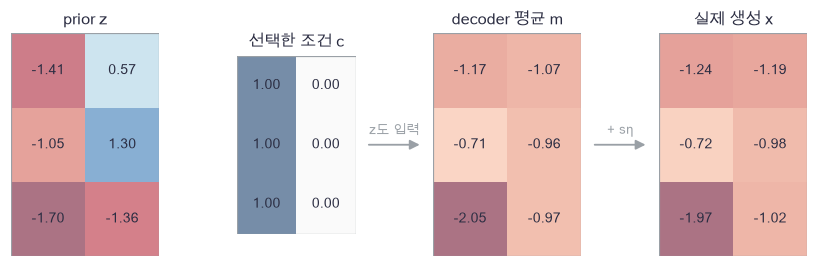

In [48]:
plot_generation_path(prior_z[:3], generation_c0[:3], reference_mean[:3], reference_generated[:3])

🔍 **확인** · 마지막에 더하는 잡음도 모델의 정의입니다. 복원 시 μ를 decoder에 넣은 값, prior z의 decoder 평균, 관측 잡음까지 더한 생성 표본은 서로 다른 결과입니다. 이 절은 실제 학습된 모델에서 마지막 두 가지를 비교합니다.

📎 **진단 수식** · $\bar\mu_{cj}$는 조건 c 안의 encoder 평균들을 다시 평균한 값입니다. 조건마다 다른 평균만 외워도 잠재를 많이 쓴 것처럼 보이지 않도록

$$V_j=\frac1N\sum_c\sum_{n:c_n=c}(\mu_{nj}-\bar\mu_{cj})^2,\qquad
S_j=\sqrt{\operatorname{mean}_{z,c,d}\left[
\left(\frac{m_d(z+h e_j,c)-m_d(z-h e_j,c)}{2h}\right)^2\right]}$$

를 씁니다. $V_j$는 조건 안의 경험 분산을 자료 비중으로 평균한 값입니다. $S_j$는 고정 prior 표본·두 조건·관측 두 좌표에 대한 수치 민감도 RMS이며 $h=10^{-3}$입니다. 둘 다 `(L,)`입니다. $V_j=0$이어도 입력에 따른 q의 **분산 변화**가 정보를 담을 수 있으므로 이 값 하나가 정보량은 아닙니다.

통제 모형에서는 $W_\mu,b_\mu,W_\ell,b_\ell=0$으로 q를 prior로 만들고, $W_d$의 **잠재 입력 행**을 0으로 만들어 z 경로를 끊습니다. 그러면 정확히 KL=0, V=0, S=0입니다. 조건 입력 행은 남으므로 품종별 평균은 여전히 다를 수 있습니다. 이 통제는 학습이 저절로 collapse한 증거가 아니라 **진단의 뜻을 확인하려고 직접 만든 예**입니다.

> **코드**
>
> - `np.tile(c,(N,1))`은 조건 행을 N번 반복합니다. `np.repeat(z,2,axis=0)`은 각 잠재 행을 두 번씩 연속 복제합니다. 짝을 맞춰 같은 z에 조건 0·1을 붙입니다.
> - `selected = condition[:,label] == 1`은 해당 조건의 관측만 고르는 참/거짓 마스크입니다. 아래 자료에는 두 조건이 모두 있습니다.

In [49]:
def latent_diagnostics(x, condition, p, prior_z, difference_step=1e-3):
    """조건 안의 μ 분산과 decoder 평균의 z별 수치 민감도. 두 지표 모두 (L,)입니다."""
    # 쓰는 것: encode_cvae, decode_cvae (3절)
    mu, logvar, cache = encode_cvae(x, condition, p)
    within_variance = np.zeros(mu.shape[1])
    for label in range(condition.shape[1]):
        selected = condition[:, label] == 1
        within_variance += selected.mean() * mu[selected].var(axis=0)
    sensitivity = np.zeros(mu.shape[1])
    repeated_c = np.tile(np.eye(condition.shape[1]), (len(prior_z), 1))
    repeated_z = np.repeat(prior_z, condition.shape[1], axis=0)
    for j in range(mu.shape[1]):
        plus = repeated_z.copy()
        minus = repeated_z.copy()
        plus[:, j] += difference_step
        minus[:, j] -= difference_step
        mean_plus, cache_plus = decode_cvae(plus, repeated_c, p)
        mean_minus, cache_minus = decode_cvae(minus, repeated_c, p)
        derivative = (mean_plus - mean_minus) / (2.0 * difference_step)
        sensitivity[j] = np.sqrt(np.mean(derivative**2))
    return within_variance, sensitivity

In [50]:
# 쓰는 것: reference_model, prior_z (5절) · test_x, test_c, test_eps, observation_sd (4절)
# 쓰는 것: evaluate_cvae, decode_cvae, latent_diagnostics (3–5절)
collapsed_control = {}
for name in reference_model:
    collapsed_control[name] = reference_model[name].copy()
for name in ['Wmu', 'bmu', 'Wlv', 'blv']:
    collapsed_control[name] = np.zeros_like(collapsed_control[name])
collapsed_control['Wd'][:2] = 0.0
control_score = evaluate_cvae(test_x, test_c, collapsed_control, test_eps, observation_sd)
control_variance, control_sensitivity = latent_diagnostics(test_x, test_c, collapsed_control, prior_z)
np.testing.assert_allclose(control_score['kl'], 0.0)  # 검산: 통제 q=prior의 KL=0
np.testing.assert_allclose(control_variance, 0.0)  # 검산: 모든 입력의 μ=0이므로 조건 안 분산=0
np.testing.assert_allclose(control_sensitivity, 0.0)  # 검산: 잠재 입력 행을 끊으면 decoder z 민감도=0
control_m0, control_cache0 = decode_cvae(prior_z, np.tile([[1.0, 0.0]], (256, 1)), collapsed_control)
control_m1, control_cache1 = decode_cvae(prior_z, np.tile([[0.0, 1.0]], (256, 1)), collapsed_control)
np.testing.assert_allclose(control_m0, np.repeat(control_m0[:1], 256, axis=0))  # 검산: 같은 조건에서는 z가 달라도 평균이 같음
print("직접 만든 collapse 통제의 정확한 세 지표 검산 통과")
print("통제의 조건별 평균 차이:", np.round(control_m1[0] - control_m0[0], 3))

직접 만든 collapse 통제의 정확한 세 지표 검산 통과
통제의 조건별 평균 차이: [2.554 0.308]


In [51]:
# 쓰는 것: all_models, all_scores, beta_names, test_x, test_c (4절) · prior_z, control_score/variance/sensitivity (5절)
# 쓰는 것: latent_diagnostics (5절 정의)
kl_dimensions = []
within_variances = []
decoder_sensitivities = []
for candidate in range(4):
    model = all_models[candidate][0]
    variance, sensitivity = latent_diagnostics(test_x, test_c, model, prior_z)
    kl_dimensions.append(all_scores[candidate][0]['kl_dim'])
    within_variances.append(variance)
    decoder_sensitivities.append(sensitivity)
kl_dimensions.append(control_score['kl_dim'])
within_variances.append(control_variance)
decoder_sensitivities.append(control_sensitivity)
diagnostic_names = beta_names + ['경로 차단 통제']

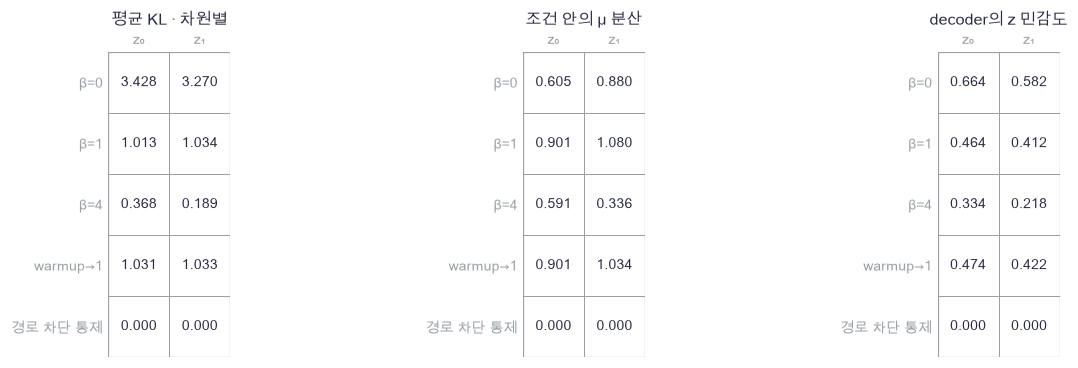

In [52]:
plot_latent_diagnostics(diagnostic_names, np.array(kl_dimensions), np.array(within_variances), np.array(decoder_sensitivities))

🔍 **확인** · β=4의 압축 경향이 어느 차원의 지표에서 관측되는지 보세요. 지표가 작다는 말과 정확히 0인 통제는 구분합니다. β=4에서 완전 collapse가 나타나지 않아도 오류가 아닙니다. 반대로 양의 KL이 항상 생성 품질이나 해석 가능한 축을 보장하지도 않습니다. 이 표는 첫 seed의 진단이며 3 seed 전체의 보편적 순위를 뜻하지 않습니다.

다음 그림은 같은 prior z·관측 η 256개를 모든 후보에 넣습니다. 조건마다 256점이며, **위에는 decoder 평균**, **아래에는 실제 생성**을 둡니다. 회색 점은 독립 test입니다. 모든 판에서 동일한 좌표 범위를 사용합니다. 휘어진 띠를 채우는지, 멀리 벗어나는 점이 있는지, 관측 잡음이 어느 폭을 더하는지 보세요.

In [53]:
# 쓰는 것: all_models (4절), prior_z, generation_c0, generation_c1, observation_eta, observation_sd (생성 설정) · decode_cvae (3절)
generation_means = []
generation_samples = []
for candidate_models in all_models:
    model = candidate_models[0]
    means_for_conditions = []
    samples_for_conditions = []
    for condition in [generation_c0, generation_c1]:
        mean, cache = decode_cvae(prior_z, condition, model)
        means_for_conditions.append(mean)
        samples_for_conditions.append(mean + observation_sd * observation_eta)
    generation_means.append(means_for_conditions)
    generation_samples.append(samples_for_conditions)

In [54]:
# 쓰는 것: generation_means, generation_samples (생성 계산) · test_x (4절)
points_for_limits = [test_x]
for means_for_conditions in generation_means:
    for values in means_for_conditions:
        points_for_limits.append(values)
for samples_for_conditions in generation_samples:
    for values in samples_for_conditions:
        points_for_limits.append(values)
all_points = np.concatenate(points_for_limits, axis=0)
plot_low = all_points.min(axis=0) - 0.2
plot_high = all_points.max(axis=0) + 0.2
generation_bounds = [plot_low[0], plot_high[0], plot_low[1], plot_high[1]]

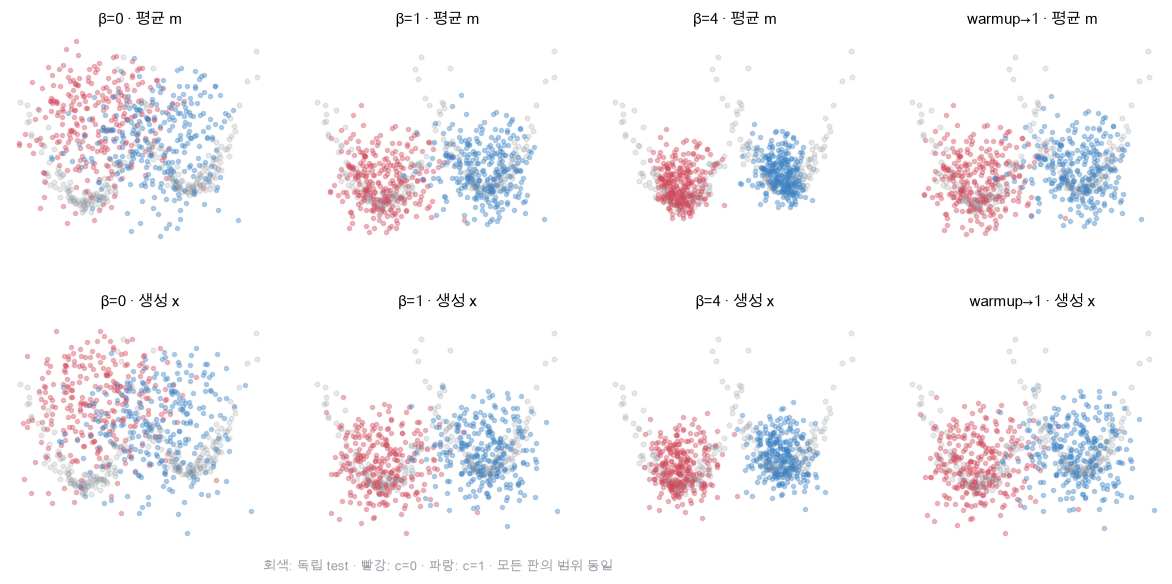

In [55]:
plot_generated_comparison(test_x, test_c, generation_means, generation_samples, beta_names, generation_bounds)

🔍 **결과를 읽는 범위** · β=0에서 복원이 작아도 prior 생성이 같은 정도로 맞는지는 그림을 별도로 보아야 합니다. β=1·4·warmup의 결과 역시 이 자료·모델·고정 예산에서 나온 관측입니다. 통계 하나나 점 그림 하나로 생성 품질 전체를 정하지 않습니다([37번](37_generative_evaluation.ipynb)).

각 (z,c)의 관측분포는 평균만 학습하고 분산 $s^2$은 고정한 Gaussian입니다. z를 적분한 주변 분포 $p_\theta(x\mid c)$는 Gaussian일 필요가 없습니다. β-VAE라는 이름을 썼다고 잠재 축이 실제 생성 요인 t나 품종과 일대일 대응하도록 보장되는 것은 아닙니다. 품종은 이미 c로 제공되며, 잠재 좌표의 방향·부호도 유일하지 않습니다.

### ✏️ 연습 5 · 평균에서 실제 관측을 생성합니다

prior에서 이미 뽑은 z를 decoder에 넣어 얻은 mean입니다. 독립 표준정규 η를 더하세요.

In [56]:
def exercise_observation_sample(mean, observation_sd, eta):
    """고정 Gaussian decoder의 실제 관측 표본을 만듭니다."""
    ### 구현할 내용: Gaussian 관측 평균 + 표준편차 × 표준정규 잡음
    raise NotImplementedError
    return sample

In [57]:
# 쓰는 것: run_check (준비 셀) · exercise_observation_sample (바로 위)
def check_observation_sample(fn):
    """작은 독립 손계산으로 연습의 주장을 확인합니다."""
    actual = fn(np.array([[1.0, -1.0]]), 0.2, np.array([[2.0, -0.5]]))
    np.testing.assert_allclose(actual, [[1.4, -1.1]])  # 검산: [1,-1]+0.2×[2,-0.5]
    print("decoder 평균과 실제 관측 표본 구분 통과")

run_check(check_observation_sample, exercise_observation_sample, hint='mean만 반환하면 관측 잡음이 빠집니다.')

☐ exercise_observation_sample: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: mean만 반환하면 관측 잡음이 빠집니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
sample = mean + observation_sd * eta
```

</details>

## ✏️ 끝 연습 · 다른 모양에서도 한두 줄을 확인합니다

각 문제는 위에서 나온 식 하나만 바꿉니다. 본문 학습 파라미터와 난수 상태는 수정하지 않습니다.

### ✏️ 연습 A · 모인 Gaussian의 분산을 계산합니다

동일 비중의 q들을 섞은 주변 분산은 각 분산의 평균만이 아닙니다. μ의 흩어짐도 넣으세요.

In [58]:
def exercise_aggregate_variance(mu, variance):
    """동일 비중 Gaussian 혼합의 좌표별 분산을 구합니다."""
    ### 구현할 내용: E[σ²+μ²] − E[μ]²
    raise NotImplementedError
    return result

In [59]:
# 쓰는 것: run_check (준비 셀) · exercise_aggregate_variance (바로 위)
def check_aggregate_variance(fn):
    """작은 독립 손계산으로 연습의 주장을 확인합니다."""
    actual = fn(np.array([[-0.8], [0.8]]), np.array([[0.36], [0.36]]))
    np.testing.assert_allclose(actual, [1.0])  # 검산: 0.36+0.64=1
    print("모인 q의 전체 분산 통과")

run_check(check_aggregate_variance, exercise_aggregate_variance, hint='조건부 분산과 평균의 흩어짐을 모두 포함합니다.')

☐ exercise_aggregate_variance: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 조건부 분산과 평균의 흩어짐을 모두 포함합니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
result = (variance + mu**2).mean(axis=0) - mu.mean(axis=0)**2
```

</details>

### ✏️ 연습 B · warmup의 경계를 넘습니다

`warmup_steps>0`일 때 계수를 만들고, 0이면 첫 갱신부터 목표값을 반환하세요.

In [60]:
def exercise_warmup(step, target_beta, warmup_steps):
    """0부터 세는 갱신 번호의 KL 계수를 반환합니다."""
    if warmup_steps == 0:
        return float(target_beta)
    ### 구현할 내용: 목표값을 넘지 않는 선형 증가
    raise NotImplementedError
    return beta

In [61]:
# 쓰는 것: run_check (준비 셀) · exercise_warmup (바로 위)
def check_warmup(fn):
    """작은 독립 손계산으로 연습의 주장을 확인합니다."""
    actual = [fn(0, 2.0, 4), fn(2, 2.0, 4), fn(8, 2.0, 4), fn(0, 2.0, 0)]
    np.testing.assert_allclose(actual, [0.0, 1.0, 2.0, 2.0])  # 검산: 시작·중간·상한·warmup 없음
    print("warmup 경계 변형 통과")

run_check(check_warmup, exercise_warmup, hint='min으로 증가량을 1에서 멈춥니다.')

☐ exercise_warmup: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: min으로 증가량을 1에서 멈춥니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
beta = target_beta * min(step / warmup_steps, 1.0)
```

</details>

### ✏️ 연습 C · 관측의 두 미분 경로를 합칩니다

`encoder_dx`는 encoder에서 돌아온 기여입니다. 정답 X의 직접 기여를 더하세요.

In [62]:
def exercise_input_gradient(encoder_dx, dm):
    """X의 encoder 경로와 재구성 정답 경로를 합칩니다."""
    ### 구현할 내용: encoder 경로 − decoder 평균에 대한 기울기
    raise NotImplementedError
    return dx

In [63]:
# 쓰는 것: run_check (준비 셀) · exercise_input_gradient (바로 위)
def check_input_gradient(fn):
    """작은 독립 손계산으로 연습의 주장을 확인합니다."""
    actual = fn(np.array([[0.3, -0.2]]), np.array([[0.5, 0.1]]))
    np.testing.assert_allclose(actual, [[-0.2, -0.3]])  # 검산: [0.3,-0.2]−[0.5,0.1]
    print("관측 입력의 두 경로 합 통과")

run_check(check_input_gradient, exercise_input_gradient, hint='(m−x)²에서 x의 직접 미분은 m의 미분과 부호가 반대입니다.')

☐ exercise_input_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: (m−x)²에서 x의 직접 미분은 m의 미분과 부호가 반대입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dx = encoder_dx - dm
```

</details>

### ✏️ 연습 D · 조건 안의 평균 변동만 셉니다

각 행에서 그 품종의 평균을 뺀 centered_mu를 받았습니다. 잠재 축별 경험 분산을 구하세요.

In [64]:
def exercise_within_variance(centered_mu):
    """조건 안에서 중심화된 μ의 좌표별 제곱 평균입니다."""
    ### 구현할 내용: 제곱한 뒤 관측 축 평균
    raise NotImplementedError
    return variance

In [65]:
# 쓰는 것: run_check (준비 셀) · exercise_within_variance (바로 위)
def check_within_variance(fn):
    """작은 독립 손계산으로 연습의 주장을 확인합니다."""
    actual = fn(np.array([[-1.0, 0.0], [1.0, 0.0], [-2.0, 0.0], [2.0, 0.0]]))
    np.testing.assert_allclose(actual, [2.5, 0.0])  # 검산: (1+1+4+4)/4=2.5
    print("조건 안의 잠재 평균 분산 통과")

run_check(check_within_variance, exercise_within_variance, hint='mean(axis=0)으로 관측 축만 줄입니다.')

☐ exercise_within_variance: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: mean(axis=0)으로 관측 축만 줄입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
variance = (centered_mu**2).mean(axis=0)
```

</details>

## ✏️ 준비도 · 설명·수식·구현·변형 검산

1. **설명:** q가 입력마다 다르다는 말과 모인 q가 prior와 비슷하다는 말은 어떻게 다른가요? 작은 KL만으로 생성 품질이나 collapse를 확정할 수 없는 이유는 무엇인가요?
2. **수식:** $R+\beta K$, $R+K$, $m(z,c)$, $m(z,c)+s\eta$를 각각 학습 목적·공통 평가·평균·실제 생성에 연결할 수 있나요? β≥1일 때 하한 관계도 적어 보세요.
3. **구현:** ε를 고정한 전체 backward에서 log 분산의 두 항, 조건의 두 경로, 관측의 정답 직접 경로를 찾아 설명할 수 있나요?
4. **변형 검산:** latent=3이나 조건 열 3개로 작은 모델을 바꿨을 때 shape와 전체 중심차분을 다시 검사할 수 있나요? 평가 반복 K만 늘렸을 때 MC SE와 학습 seed SD 중 어떤 값의 의미가 달라지나요?

### 📎 원문과 다음 연결

- [Kingma·Welling, Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114): 재매개화와 변분 목적의 출발점입니다. 여기서는 25번의 식을 작은 Gaussian 관측에 다시 구현했습니다.
- [Higgins 외, β-VAE — 저자 공개 페이지](https://www.matthey.me/publication/beta_vae/): KL 계수로 복원과 잠재 제약의 비중을 조절하는 배경입니다. 이 노트북의 합성 실험은 원 논문의 disentanglement 벤치마크 재현이 아닙니다.
- [Bowman 외, Generating Sentences from a Continuous Space](https://arxiv.org/abs/1511.06349): KL 비용을 점차 올리는 학습 방법을 사용합니다. 여기서는 문장 모델 없이 계수 규칙만 작은 VAE에서 비교합니다.
- [Sohn 외, Learning Structured Output Representation using Deep Conditional Generative Models](https://papers.nips.cc/paper_files/paper/2015/hash/8d55a249e6baa5c06772297520da2051-Abstract.html): 조건부 변분 생성의 배경입니다. 이번 예제는 조건에 의존하지 않는 고정 prior를 쓴 간단한 모형입니다.

[25 VAE](25_vae.ipynb)에서 기대값을 구현하고, [27 Monte Carlo](27_monte_carlo_gradients.ipynb)에서 표본 미분과 SE를 다시 검산한 뒤, [37 생성 평가](37_generative_evaluation.ipynb)에서 지표가 놓치는 실패를 살펴보세요. 26번은 같은 모델의 분포와 사용 경로를 읽는 연결 자료입니다.